In [27]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## printing the head of the dataset to show it loaded correctly

In [28]:
# loading the data set and add headers to make it more readable 
data = pd.read_csv("../../DataSet/iris.data", 
header=None, 
names=["sepal_length", 
        "sepal_width", 
        "petal_length", 
        "petal_width", 
        "species"])

# printing head or the first few rows to see if it works
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## pick file path and create a text file with some basic information about the dataset

In [29]:
import os

# create a txr file called summary it contains the row count
# min max and averages

file_path = "../../DataSet/summary.txt"

# store the summary stats in a DataFrame
summary = pd.DataFrame({
    "Min": data.min(),
    "Max": data.max(),
    "Average": data.select_dtypes(include=[np.number]).mean().round(2).astype(object).reindex(data.columns).fillna("")
})

# write the summary statistics to the text file
with open(file_path, "w") as f:
    f.write(f"Row count: {data.shape[0]}\n\n")
    f.write(summary.to_string() + "\n")

# print the summary file to see if it works
with open(file_path, "r") as f:
    print(f.read())


Row count: 150

                      Min             Max Average
sepal_length          4.3             7.9    5.84
sepal_width           2.0             4.4    3.05
petal_length          1.0             6.9    3.76
petal_width           0.1             2.5     1.2
species       Iris-setosa  Iris-virginica        



## using pandas to see if there are any N/A values and if so drop them from the dataset

In [30]:
print(data.shape)
print("\n")
print(data.info())
print("\n")

# check for missing values and drop them if any
if data.isnull().sum().sum() > 0:
    data.dropna(inplace=True)

print(data.isnull().sum())


# check for duplicates and drop them if any
if data.duplicated().sum() > 0:
    data.drop_duplicates(inplace=True)  

print(data.duplicated().sum())

(150, 5)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
0


## save the cleaned data

In [31]:
# save as clean_iris.csv
file_path = "../../DataSet/clean_iris.csv"
data.to_csv(file_path, index=False)


## Phase four

Count how many flowers of each species manually with a for loop

In [55]:
species_counts = {}

for species in data["species"]:
    if species in species_counts:
        species_counts[species] += 1
    else:
        species_counts[species] = 1

print(species_counts)

{'Iris-setosa': 48, 'Iris-versicolor': 50, 'Iris-virginica': 49}


Categorize flowers (If/Else)
Petal length < 2 → “Short Petal”
o Petal length 2–5 → “Medium Petal”
o Petal length > 5 → “Long Petal”

In [54]:

# if 'petal_length' in data.columns:
#     data['petal_category'] = pd.cut(data['petal_length'], 
#                                     bins=[-np.inf, 2, 5, np.inf], 
#                                     labels=['Short Petal', 'Medium Petal', 'Long Petal'])

# print(data[['petal_length', 'petal_category']].tail())

petal_category = []

for petal_length in data["petal_length"]:
    if petal_length < 2:
        petal_category.append("Short Petal")
    elif petal_length <= 5:
        petal_category.append("Medium Petal")
    else:
        petal_category.append("Long Petal")

data["petal_category"] = petal_category

print(data[["petal_length", "petal_category"]].tail())

     petal_length petal_category
145           5.2     Long Petal
146           5.0   Medium Petal
147           5.2     Long Petal
148           5.4     Long Petal
149           5.1     Long Petal


Pandas Analysis:
o Calculate mean, median, min, max of sepal and petal lengths.
o Group by species and compute averages

In [ ]:

data.groupby('species').agg({
    'sepal_length': ['mean', 'median', 'min', 'max'],
    'petal_length': ['mean', 'median', 'min', 'max']
})

sepal_length                  petal_length                 
                        mean median  min  max         mean median  min  max
species                                                                    
Iris-setosa         5.010417    5.0  4.3  5.8     1.462500   1.50  1.0  1.9
Iris-versicolor     5.936000    5.9  4.9  7.0     4.260000   4.35  3.0  5.1
Iris-virginica      6.604082    6.5  4.9  7.9     5.561224   5.60  4.5  6.9

 Visualizations (matplotlib / pandas):
o Histogram of petal lengths.
o Bar chart of average sepal length per species.
o Create a boxplot and answer the following questions:
▪ Which species has the smallest range of petal lengths?
▪ Which species shows the largest spread in petal length values?
3
▪ How do the medians of the three species compare? What does
this suggest about their flower sizes?
o Do sepal length and sepal width appear strongly correlated? Explain why
or why not using evidence from a scatter plot.
o Based on the scatter, boxplot, and histogram, which flower features
(sepal length, sepal width, petal length, petal width) seem most useful
for separating the species?

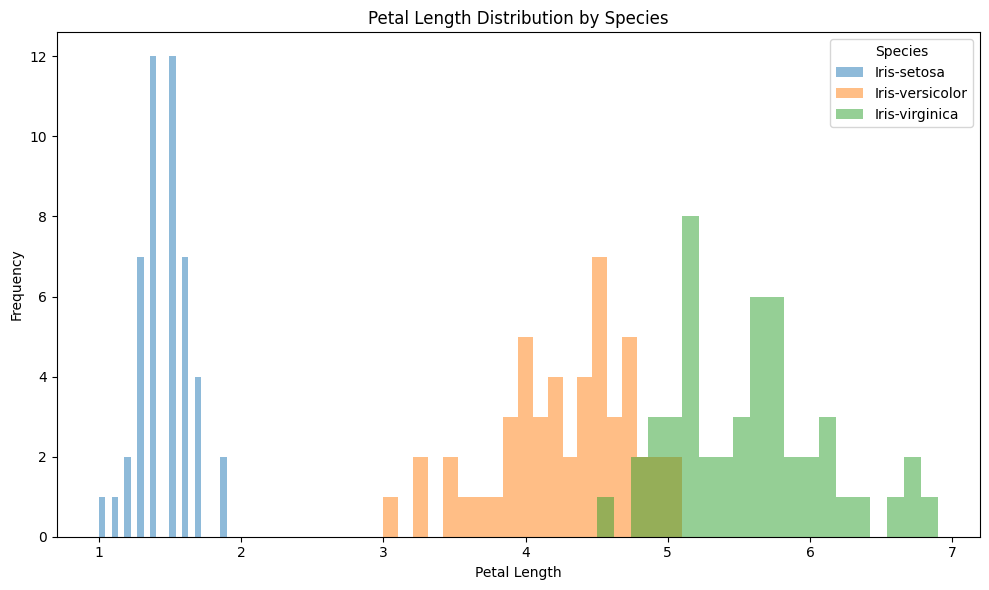

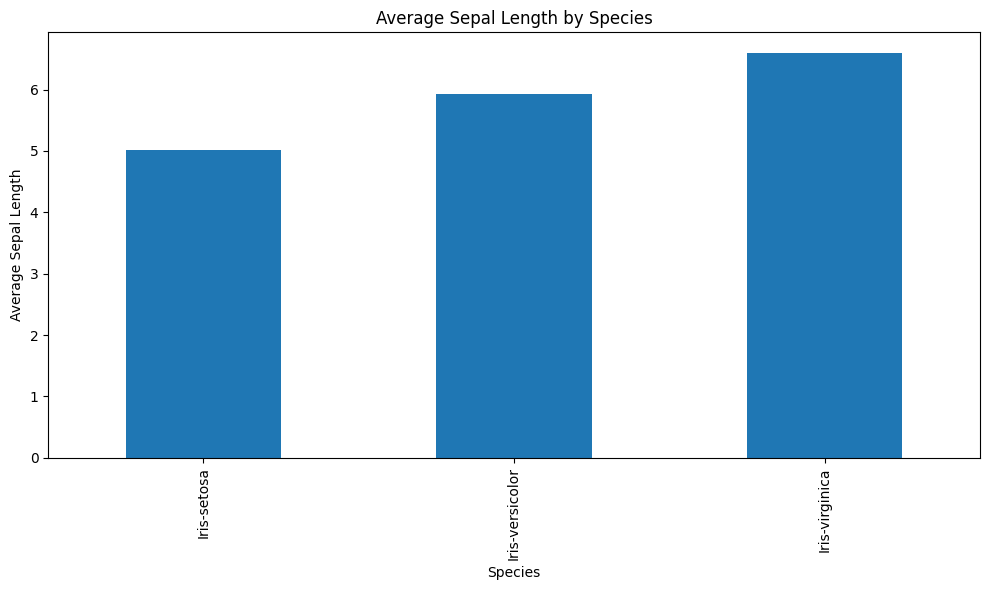

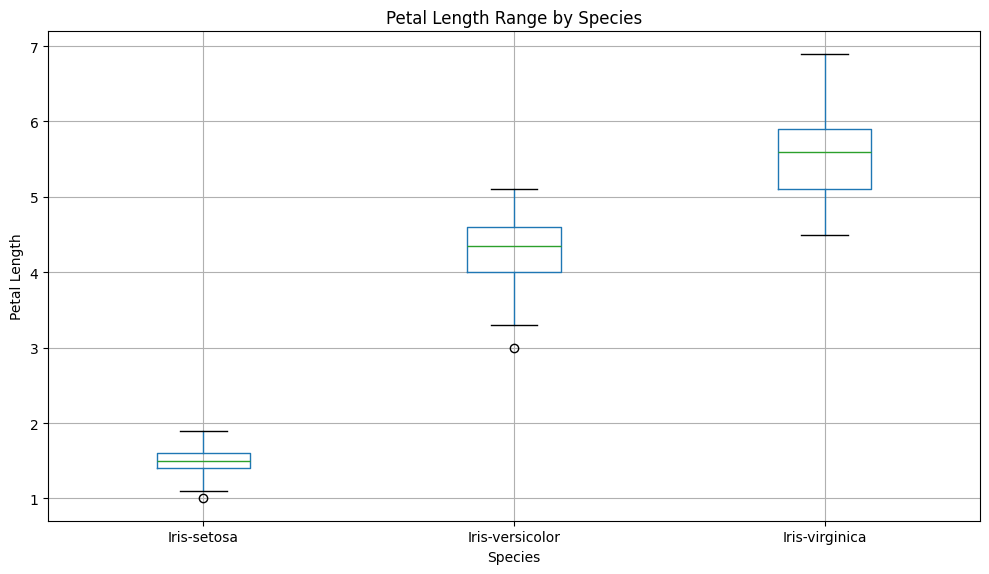

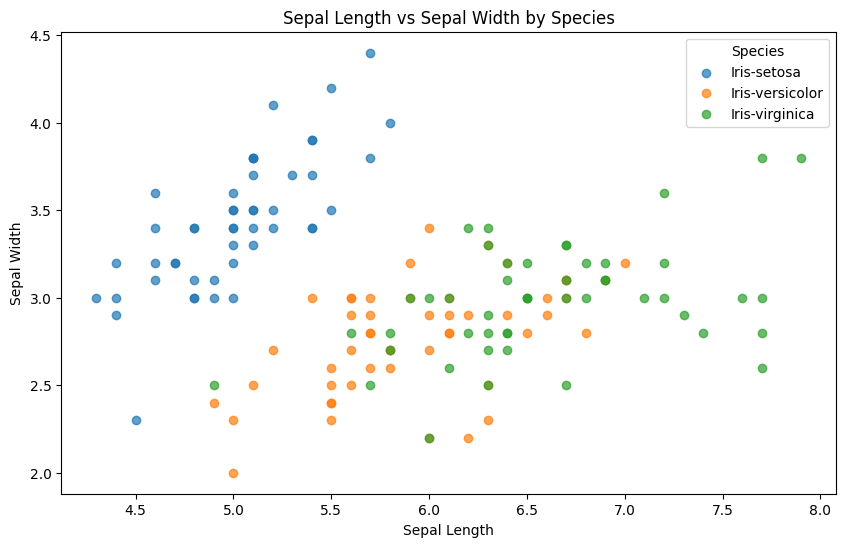

In [52]:
# Plot petal-length distributions for each species.
fig, ax = plt.subplots(figsize=(10, 6))
for species in data["species"].unique():
    subset = data[data["species"] == species]
    ax.hist(subset["petal_length"], bins=20, alpha=0.5, label=species)

ax.set_title("Petal Length Distribution by Species")
ax.set_xlabel("Petal Length")
ax.set_ylabel("Frequency")
ax.legend(title="Species")
fig.tight_layout()
plt.show()

# Compare average sepal length in a separate chart.
mean_sepal_length = data.groupby("species")["sepal_length"].mean()
fig, ax = plt.subplots(figsize=(10, 6))
mean_sepal_length.plot(kind="bar", ax=ax)
ax.set_title("Average Sepal Length by Species")
ax.set_xlabel("Species")
ax.set_ylabel("Average Sepal Length")
fig.tight_layout()
plt.show()

# Compare petal-length ranges with a separate boxplot.
fig, ax = plt.subplots(figsize=(10, 6))
data.boxplot(column="petal_length", by="species", ax=ax)
ax.set_title("Petal Length Range by Species")
ax.set_xlabel("Species")
ax.set_ylabel("Petal Length")
fig.suptitle("")
fig.tight_layout()
plt.show()

# scatter plot to visualize the relationship between sepal length and petal length, colored by species.
fig, ax = plt.subplots(figsize=(10, 6))
for species in data["species"].unique():
    subset = data[data["species"] == species]
    ax.scatter(subset["sepal_length"], subset["sepal_width"], label=species, alpha=0.7)
ax.set_xlabel("Sepal Length")
ax.set_ylabel("Sepal Width")
ax.set_title("Sepal Length vs Sepal Width by Species")
ax.legend(title="Species")
plt.show()

## 1

Setosa has the lowest median petal length, Versicolor has the middle, and Virginica has the highest median. This suggests the shortest petals generally belong to Stosa, while the logest generaly belong to Virginica. However petal length alon doesnt etablish the overallength of the flower

## 2

Across the three species sepal length and width do not appear strongly correlated. The scatter plot shows points that are widely scatterd rather in a straight narrow line in an upward or downward pattern. flowers with similar sepal lengths can have considerably diffrent sepal widths.

## 3

Petal length does appear useful because the boxplot and histogram show that the Stosa is clearly separated from the other two species. Versicolor has shorter petals in general then Virginica, however the distribution does overlap. The sepal scatter plot shows more overlap, especially when we're looking at the diffrence between Versicolor and Virginica, this makes sepal less useful for distinguishing those species.

In [53]:
file_path = "../../DataSet/iris_classes.csv"
data.to_csv(file_path, index=False)